# Computational Lab 3 — Matrix diffusion and exponential evolution

The heat equation and Fick's second law become a linear system of ordinary
differential equations after space is discretized. This lab constructs that
system from a discrete gradient, relates it directly to Fick's first law, and
evolves it with a matrix exponential.

**Learning goals**

1. construct gradient and Laplacian matrices on a periodic grid;
2. derive the matrix diffusion equation from flux and continuity;
3. evaluate $\exp(DLt)$ through the eigendecomposition of $L$; and
4. verify conservation, stability, and the semigroup property.

The field $u$ can represent particle concentration. With $D\to\alpha$, the
same evolution applies to temperature in a homogeneous material. For physical
heat flux, Fourier's law uses thermal conductivity rather than thermal
diffusivity.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "lecture-notes" / "main.tex").exists()
)
OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})

## 1. From Fick's law to a matrix ODE

Divide a periodic one-dimensional domain into $N$ cells. Define the incidence
matrix $B$ so that row $i$ subtracts cell $i$ from cell $i+1$ (indices wrap
periodically). Then

\[
    G=\frac{B}{\Delta x},\qquad
    \mathbf j=-D G\mathbf u
\]

are the discrete gradient and face-centered Fick flux. Finite-volume
continuity gives

\[
    \frac{d\mathbf u}{dt}
    =\frac{1}{\Delta x}B^T\mathbf j
    =D L\mathbf u,
    \qquad
    L=-\frac{B^TB}{\Delta x^2}.
\]

The factorization immediately shows that $L$ is symmetric negative
semidefinite. Its zero mode is the constant vector, which expresses
conservation on the periodic domain.

In [2]:
domain_length = 10.0
cell_count = 64
spacing = domain_length / cell_count
coordinate = -domain_length / 2.0 + spacing * (0.5 + np.arange(cell_count))
face_coordinate = -domain_length / 2.0 + spacing * (1.0 + np.arange(cell_count))
diffusivity = 0.80

# B maps cell values to forward differences at faces.
incidence = np.zeros((cell_count, cell_count))
row = np.arange(cell_count)
incidence[row, row] = -1.0
incidence[row, (row + 1) % cell_count] = 1.0
gradient = incidence / spacing
laplacian = -(incidence.T @ incidence) / spacing**2

constant = np.ones(cell_count)
assert np.allclose(laplacian, laplacian.T)
assert np.allclose(laplacian @ constant, 0.0)
assert np.allclose(laplacian, -(gradient.T @ gradient))

print("matrix shape:", laplacian.shape)
print("nonzero entries:", np.count_nonzero(laplacian))
print("maximum row-sum magnitude:", np.max(np.abs(laplacian.sum(axis=1))))

matrix shape: (64, 64)
nonzero entries: 192
maximum row-sum magnitude: 0.0


## 2. The matrix exponential

For constant $D$ and $L$, the exact semidiscrete solution is

\[
    \mathbf u(t)=P(t)\mathbf u(0),\qquad
    P(t)=\exp(DLt).
\]

Because $L=Q\Lambda Q^T$ is real symmetric,

\[
    P(t)=Q\,\mathrm{diag}\!\left(e^{D\lambda_k t}\right)Q^T.
\]

Every nonconstant mode has $\lambda_k<0$ and decays exponentially. The
constant mode has $\lambda=0$ and is preserved. This eigendecomposition is a
transparent matrix-exponential implementation and requires no time stepping.

In [3]:
eigenvalue, eigenvector = np.linalg.eigh(laplacian)


def propagator(time_value):
    # Return exp(D L t) using the symmetric eigendecomposition of L.
    modal_factor = np.exp(diffusivity * eigenvalue * time_value)
    return (eigenvector * modal_factor) @ eigenvector.T


# A nonnegative, nonuniform initial field; periodic distance keeps it smooth
# across the boundary.
def periodic_distance(values, center):
    return (values - center + domain_length / 2.0) % domain_length - domain_length / 2.0


initial_field = (
    1.0
    + 3.0 * np.exp(-(periodic_distance(coordinate, -1.5) / 0.55) ** 2)
    + 1.4 * np.exp(-(periodic_distance(coordinate, 2.2) / 0.85) ** 2)
)
sample_times = np.array([0.0, 0.25, 1.0, 3.0])
field = np.array([propagator(t) @ initial_field for t in sample_times])

# A denser time array is used only for the space-time plot.
evolution_times = np.linspace(0.0, 3.0, 121)
evolution = np.array([propagator(t) @ initial_field for t in evolution_times])

## 3. Flux, continuity, and conservation checks

The matrix formulation retains the same physical bookkeeping as the
finite-volume random walk. We independently form the face flux and substitute
it into continuity. We also test the exponential identity
$P(t+s)=P(t)P(s)$.

In [4]:
check_time = 1.0
check_field = propagator(check_time) @ initial_field
face_flux = -diffusivity * gradient @ check_field
rhs_from_flux = incidence.T @ face_flux / spacing
rhs_from_laplacian = diffusivity * laplacian @ check_field

field_integral = spacing * np.sum(field, axis=1)
semigroup_error = np.linalg.norm(
    propagator(0.7 + 0.4) - propagator(0.7) @ propagator(0.4),
    ord=np.inf,
)
maximum_eigenvalue = np.max(eigenvalue)
minimum_eigenvalue = np.min(eigenvalue)

assert np.all(eigenvalue <= 1.0e-12)
assert np.count_nonzero(np.isclose(eigenvalue, 0.0, atol=1.0e-12)) == 1
assert np.allclose(rhs_from_flux, rhs_from_laplacian)
assert np.allclose(field_integral, field_integral[0], rtol=1.0e-13)
assert semigroup_error < 1.0e-12

print(f"L eigenvalue interval       = [{minimum_eigenvalue:.6f}, {maximum_eigenvalue:.3e}]")
print(f"conserved integral          = {field_integral[0]:.12f}")
print(f"largest integral drift      = {np.max(np.abs(field_integral - field_integral[0])):.3e}")
print(f"semigroup infinity-norm err = {semigroup_error:.3e}")

L eigenvalue interval       = [-163.840000, 7.644e-16]
conserved integral          = 15.033768936572
largest integral drift      = 3.197e-14
semigroup infinity-norm err = 1.054e-15


## 4. Why exponential evolution is useful

Explicit Euler would use

\[
    \mathbf u^{m+1}=(I+D\Delta tL)\mathbf u^m.
\]

For this one-dimensional centered Laplacian it is stable only when
$D\Delta t/\Delta x^2\leq 1/2$. The exponential propagator has modal factors
$e^{D\lambda_k t}\in(0,1]$ for every $t\geq0$, so it does not have this time-step
stability restriction. Its cost is constructing or applying the exponential;
for large sparse systems, specialized Krylov or implicit methods are normally
used instead of a dense eigendecomposition.

In [5]:
euler_limit = spacing**2 / (2.0 * diffusivity)
stable_step = 0.8 * euler_limit
unstable_step = 1.2 * euler_limit
stable_amplification = 1.0 + diffusivity * stable_step * eigenvalue
unstable_amplification = 1.0 + diffusivity * unstable_step * eigenvalue
exponential_amplification = np.exp(diffusivity * eigenvalue * unstable_step)

assert np.max(np.abs(stable_amplification)) <= 1.0 + 1.0e-12
assert np.max(np.abs(unstable_amplification)) > 1.0
assert np.max(np.abs(exponential_amplification)) <= 1.0 + 1.0e-12

print(f"explicit-Euler stability limit = {euler_limit:.6f} s")
print(f"spectral radius below limit     = {np.max(np.abs(stable_amplification)):.6f}")
print(f"spectral radius above limit     = {np.max(np.abs(unstable_amplification)):.6f}")
print(f"exponential spectral radius     = {np.max(np.abs(exponential_amplification)):.6f}")

explicit-Euler stability limit = 0.015259 s
spectral radius below limit     = 1.000000
spectral radius above limit     = 1.400000
exponential spectral radius     = 1.000000


## 5. Results

The Laplacian's three-band periodic structure encodes nearest-neighbour
coupling. Its nonzero modes decay, the field smooths while preserving its
integral, and Fick flux points away from local maxima.

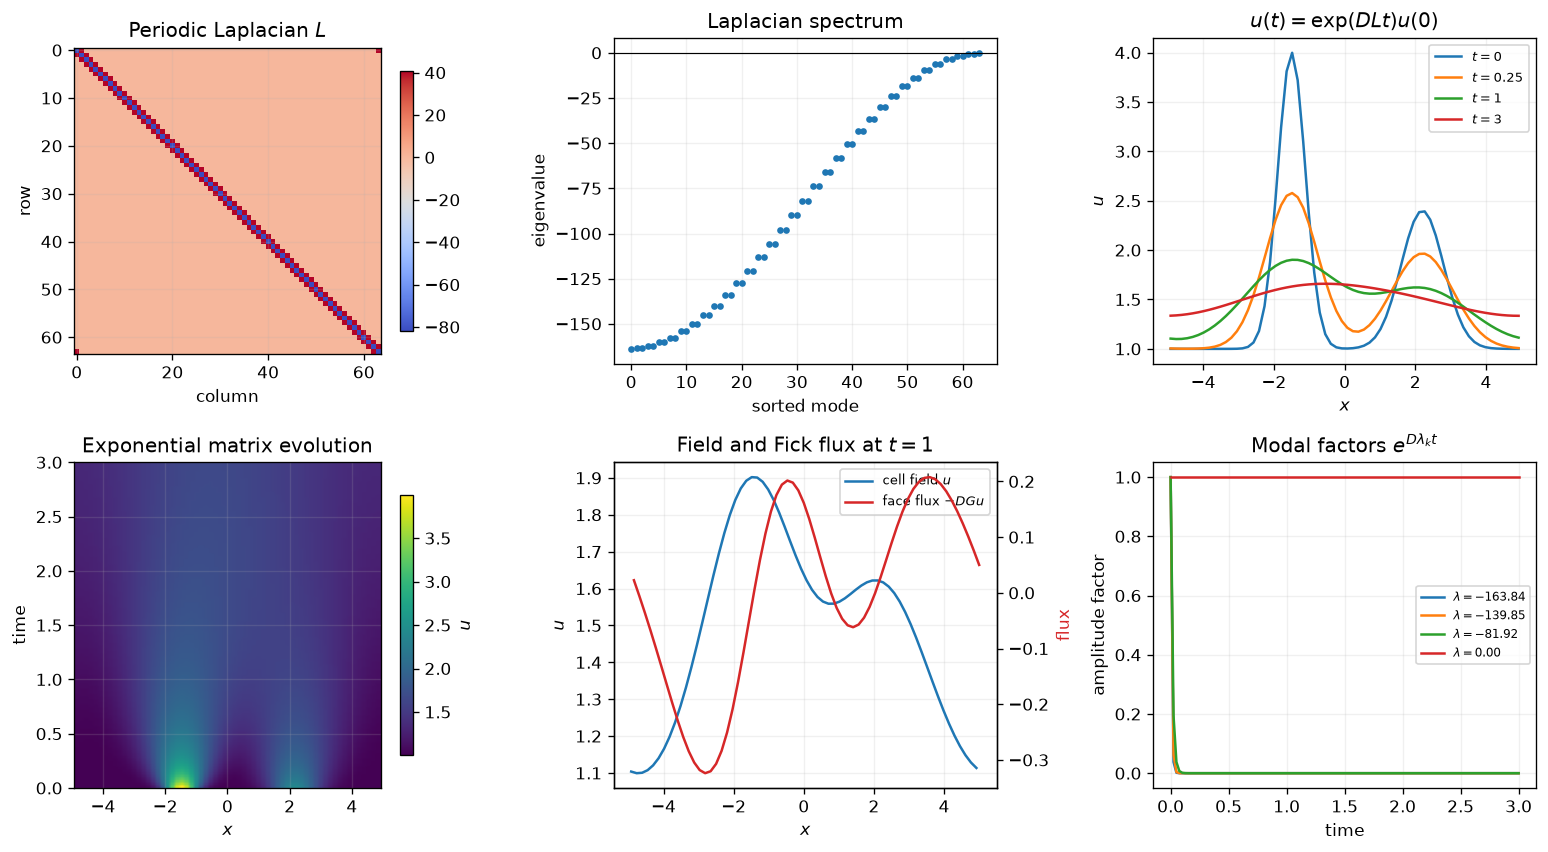

wrote lecture-notes/figures/08_brownian-motion-diffusion/lab-03-matrix-diffusion-exponential-evolution.pdf


In [6]:
figure, axes = plt.subplots(2, 3, figsize=(13.0, 7.2))

image = axes[0, 0].imshow(laplacian, cmap="coolwarm", aspect="equal")
axes[0, 0].set(title=r"Periodic Laplacian $L$", xlabel="column", ylabel="row")
figure.colorbar(image, ax=axes[0, 0], shrink=0.8)

mode_number = np.arange(cell_count)
axes[0, 1].plot(mode_number, eigenvalue, ".", label=r"$\lambda_k$")
axes[0, 1].axhline(0.0, color="black", linewidth=0.7)
axes[0, 1].set(title="Laplacian spectrum", xlabel="sorted mode", ylabel="eigenvalue")

for index, sample_time in enumerate(sample_times):
    axes[0, 2].plot(coordinate, field[index], label=rf"$t={sample_time:g}$")
axes[0, 2].set(title=r"$u(t)=\exp(DLt)u(0)$", xlabel="$x$", ylabel="$u$")
axes[0, 2].legend(fontsize=8)

space_time = axes[1, 0].imshow(
    evolution,
    origin="lower",
    aspect="auto",
    extent=[coordinate[0], coordinate[-1], evolution_times[0], evolution_times[-1]],
    cmap="viridis",
)
axes[1, 0].set(title="Exponential matrix evolution", xlabel="$x$", ylabel="time")
figure.colorbar(space_time, ax=axes[1, 0], shrink=0.8, label="$u$")

axes[1, 1].plot(coordinate, check_field, label=r"cell field $u$")
flux_axis = axes[1, 1].twinx()
flux_axis.plot(face_coordinate, face_flux, color="tab:red", label=r"face flux $-DGu$")
axes[1, 1].set(title=r"Field and Fick flux at $t=1$", xlabel="$x$", ylabel="$u$")
flux_axis.set_ylabel("flux", color="tab:red")
lines = axes[1, 1].lines + flux_axis.lines
axes[1, 1].legend(lines, [line.get_label() for line in lines], fontsize=8)

selected_modes = [0, cell_count // 4, cell_count // 2, cell_count - 1]
for mode in selected_modes:
    axes[1, 2].plot(
        evolution_times,
        np.exp(diffusivity * eigenvalue[mode] * evolution_times),
        label=rf"$\lambda={eigenvalue[mode]:.2f}$",
    )
axes[1, 2].set(title=r"Modal factors $e^{D\lambda_k t}$", xlabel="time", ylabel="amplitude factor")
axes[1, 2].legend(fontsize=7)

for axis in axes.flat:
    axis.grid(alpha=0.18)
figure.tight_layout()
output_path = OUTPUT / "lab-03-matrix-diffusion-exponential-evolution.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": "DLSU SEMPHY01", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")

## Questions and extensions

1. Starting from $\mathbf j=-DG\mathbf u$, reproduce every sign and factor of
   $\Delta x$ in $L=-B^TB/\Delta x^2$.
2. Explain why the zero eigenvalue conserves the spatial mean. What physical
   boundary condition would allow that mean to change?
3. Replace the periodic matrix by fixed-temperature (Dirichlet) boundaries.
   Which rows change, and does a constant zero mode remain?
4. Compare repeated explicit-Euler steps with `propagator(t)` below and above
   the printed stability limit.
5. For a heterogeneous diffusivity, put face coefficients in a diagonal
   matrix $D_f$. Show that the conservative operator becomes
   $-B^TD_fB/\Delta x^2$ rather than simply $D(x)L$.